In [1]:
import json
from pathlib import Path

ROOT = Path.cwd()
if not (ROOT / "profiles").is_dir() and (ROOT.parent / "profiles").is_dir():
    ROOT = ROOT.parent

In [2]:
with (ROOT / "profiles/spaceship_titanic_students/pipeline_1_1.json").open() as f:
    content = json.load(f)

In [3]:
content.keys()

dict_keys(['alloc_samples', 'args', 'async_profile', 'combined_stacks', 'combined_stacks_timeline', 'elapsed_time_sec', 'entrypoint_dir', 'filename', 'files', 'gpu', 'gpu_device', 'growth_rate', 'main_thread_id', 'max_footprint_fname', '   ', 'max_footprint_mb', 'max_footprint_python_fraction', 'memory', 'memory_stacks', 'native_allocations_mb', 'program', 'samples', 'stacks', 'start_time_absolute', 'start_time_perf'])

In [4]:
content["files"].keys()

dict_keys(['/Users/tue/Documents/10_Projects/deai-pro/spaceship_titanic_students/pipeline_1_1.py', '<exec@_internal.py:64>'])

In [5]:
lines = content["files"][content["program"]]["lines"]

In [6]:
len(lines)

114

In [7]:
lines

[{'async_task_names': [],
  'cpu_samples_list': [],
  'end_function_line': 0,
  'end_outermost_loop': 1,
  'end_region_line': 1,
  'is_coroutine': False,
  'line': '"""Raw features; logistic C=0.1. Read passenger files from input/."""\n',
  'lineno': 1,
  'memory_samples': [],
  'n_async_await_percent': 0.0,
  'n_async_concurrency_mean': 0.0,
  'n_async_concurrency_peak': 0.0,
  'n_avg_mb': 0.0,
  'n_copy_mb_s': 0.0,
  'n_core_utilization': 0.0,
  'n_cpu_percent_c': 0.0,
  'n_cpu_percent_python': 0.0,
  'n_gpu_avg_memory_mb': 0.0,
  'n_gpu_peak_memory_mb': 0.0,
  'n_gpu_percent': 0,
  'n_growth_mb': 0.0,
  'n_malloc_mb': 0.0,
  'n_mallocs': 0,
  'n_peak_mb': 0.0,
  'n_python_fraction': 0,
  'n_sys_percent': 0.0,
  'n_usage_fraction': 0.0,
  'start_function_line': 0,
  'start_outermost_loop': 1,
  'start_region_line': 1},
 {'async_task_names': [],
  'cpu_samples_list': [],
  'end_function_line': 0,
  'end_outermost_loop': 2,
  'end_region_line': 2,
  'is_coroutine': False,
  'line': '\n

In [8]:
import_lines = [l for l in lines if "import " in l["line"]]

In [9]:
len(import_lines)

10

In [10]:
for l in import_lines:
    print(l)

{'async_task_names': [], 'cpu_samples_list': [], 'end_function_line': 0, 'end_outermost_loop': 3, 'end_region_line': 3, 'is_coroutine': False, 'line': 'from pathlib import Path\n', 'lineno': 3, 'memory_samples': [], 'n_async_await_percent': 0.0, 'n_async_concurrency_mean': 0.0, 'n_async_concurrency_peak': 0.0, 'n_avg_mb': 0.0, 'n_copy_mb_s': 0.0, 'n_core_utilization': 0.0, 'n_cpu_percent_c': 0.0, 'n_cpu_percent_python': 0.0, 'n_gpu_avg_memory_mb': 0.0, 'n_gpu_peak_memory_mb': 0.0, 'n_gpu_percent': 0, 'n_growth_mb': 0.0, 'n_malloc_mb': 0.0, 'n_mallocs': 0, 'n_peak_mb': 0.0, 'n_python_fraction': 0, 'n_sys_percent': 0.0, 'n_usage_fraction': 0.0, 'start_function_line': 0, 'start_outermost_loop': 3, 'start_region_line': 3}
{'async_task_names': [], 'cpu_samples_list': [], 'end_function_line': 0, 'end_outermost_loop': 4, 'end_region_line': 4, 'is_coroutine': False, 'line': 'import numpy as np\n', 'lineno': 4, 'memory_samples': [[38293833, 1.0000381469726562], [403453958, 2.0636606216430664], 

Metric interpretation: `total_s` estimates elapsed time from sampling percentages; `share_of_runtime` is its fraction of the profiled runtime.
Python/native time identifies the type of execution at a hotspot; it alone does not establish whether vectorization or parallelism will help.
`system_s` estimates waiting time rather than directly measuring disk I/O time.
`core_utilization` measures utilization relative to the total available CPU core capacity.
`malloc_mb` is cumulative allocated memory; `n_mallocs` is zero throughout the current data and is not used for comparisons.
`peak_mb` is the largest individual line peak within a category, not the process peak, and cannot directly determine concurrency limits.
`copy_mb` measures the volume of copied data, not time spent copying.


In [11]:
def compute_total(category, lines, elapsed_time_sec):
    """Aggregate Scalene line records of one category into absolute totals.

    CPU percentages are shares of the sampled run time (~ elapsed_time_sec),
    so they are additive across lines and convert to seconds.
    """
    active = [
        l for l in lines
        if l["n_cpu_percent_python"] + l["n_cpu_percent_c"] + l["n_sys_percent"] > 0
        or l["n_malloc_mb"] > 0
    ]
    to_sec = elapsed_time_sec / 100
    python_s = sum(l["n_cpu_percent_python"] for l in active) * to_sec
    native_s = sum(l["n_cpu_percent_c"] for l in active) * to_sec
    system_s = sum(l["n_sys_percent"] for l in active) * to_sec
    total_s = python_s + native_s + system_s
    cpu_pct = sum(l["n_cpu_percent_python"] + l["n_cpu_percent_c"] for l in active)
    malloc_mb = sum(l["n_malloc_mb"] for l in active)
    return {
        "category": category,
        "n_relevant_lines": len(active),
        "total_s": total_s,
        "share_of_runtime": total_s / elapsed_time_sec if elapsed_time_sec else 0.0,
        "python_s": python_s,
        "native_s": native_s,
        "system_s": system_s,
        # Time-weighted: lines that ran longer count more.
        "core_utilization": (
            sum(l["n_core_utilization"] * (l["n_cpu_percent_python"] + l["n_cpu_percent_c"]) for l in active) / cpu_pct
            if cpu_pct else 0.0
        ),
        "malloc_mb": malloc_mb,
        "n_mallocs": sum(l["n_mallocs"] for l in active),
        # Allocation-weighted share of memory allocated by Python (vs. native) code.
        "python_alloc_fraction": (
            sum(l["n_python_fraction"] * l["n_malloc_mb"] for l in active) / malloc_mb
            if malloc_mb else 0.0
        ),
        # Peaks are not additive: the category's peak is the largest line peak.
        "peak_mb": max((l["n_peak_mb"] for l in active), default=0.0),
        "copy_mb": sum(l["n_copy_mb_s"] for l in active) * elapsed_time_sec,
    }


compute_total("import", import_lines, content["elapsed_time_sec"])

{'category': 'import',
 'n_relevant_lines': 4,
 'total_s': 1.4344518487034492,
 'share_of_runtime': 0.7125845219054082,
 'python_s': 0.289526472057876,
 'native_s': 0.7428236058008307,
 'system_s': 0.4021017708447426,
 'core_utilization': 0.07197252535284938,
 'malloc_mb': 73.66714000701904,
 'n_mallocs': 0,
 'python_alloc_fraction': 0.9757874440034544,
 'peak_mb': 45.250155448913574,
 'copy_mb': 85.76226425170898}

In [12]:
with (ROOT / "libraries/spaceship_titanic_students/pipeline_1_1.json").open() as f:
    libraries = {int(lineno): modules for lineno, modules in json.load(f)["lines"].items()}

In [13]:
# Checked in order: a line that calls a model library is "models" even if it also touches pandas,
# e.g. classifier.fit(X.iloc[rows]). builtins carry no category.
CATEGORY_PREFIXES = {
    "models": (
        "sklearn.linear_model", "sklearn.ensemble",
        "sklearn.base",  # estimator .fit()
        "sklearn.model_selection",  # CV splitting
        "sklearn.utils._param_validation",  # wraps metrics such as accuracy_score
        "lightgbm", "xgboost", "catboost",
    ),
    "data handling": (
        "pandas", "numpy",
        "sklearn.compose", "sklearn.pipeline", "sklearn.impute", "sklearn.preprocessing",
        "sklearn.utils._set_output",  # wraps transformer fit_transform / transform
    ),
    "setup": ("importlib", "pathlib"),
}


def categorize_line(line, modules):
    for category, prefixes in CATEGORY_PREFIXES.items():
        if any(module.startswith(prefixes) for module in modules):
            return category
    # Untraced lines: imports of already-loaded modules, or plain Python inside helpers
    # such as split_cabin that pandas calls via apply.
    if line.lstrip().startswith(("import ", "from ")):
        return "setup"
    return "data handling"

In [ ]:
from collections import defaultdict
import pandas as pd

lines_by_category = defaultdict(list)
for l in lines:
    lines_by_category[categorize_line(l["line"], libraries.get(l["lineno"], {}))].append(l)

totals = pd.DataFrame(
    [compute_total(category, category_lines, content["elapsed_time_sec"])
     for category, category_lines in lines_by_category.items()]
).set_index("category")
totals

,n_relevant_lines,total_s,share_of_runtime,python_s,native_s,system_s,core_utilization,malloc_mb,n_mallocs,python_alloc_fraction,peak_mb,copy_mb
category,,,,,,,,,,,,
data handling,19,0.165034,0.081983,0.020521,0.119632,0.024880,0.085748,59.703537,0,0.237566,13.892122,11.070651
setup,4,1.434452,0.712585,0.289526,0.742824,0.402102,0.071973,73.667140,0,0.975787,45.250155,85.762264
models,3,0.375070,0.186321,0.075201,0.274564,0.025304,0.093304,0.000000,0,0.000000,0.000000,0.000000


## Top 10 hotspots: cumulative cost across 25 pipelines

Read the current profiles and library traces directly and aggregate line timings by **normalized source statement** (strip indentation and decode Scalene's Unicode escapes). Statements with different variable names or parameters remain separate. Function-level and line-level timings are not added together.

Here, an "operation" is a source-statement pattern: the same `classifier.fit(...)` statement can represent different models. The ranking measures cumulative cost; it **does not establish computational equivalence or cacheability**. Module call counts are not used to apportion time. System time is retained so that total time = Python + native + system.

Only source statements in the pipeline files are ranked. Other files and unattributed time are reported separately. All timings estimate costs under profiling, not unprofiled benchmark runtimes.


In [15]:
import re
import pandas as pd
from IPython.display import display

PROFILE_DIR = ROOT / "profiles/spaceship_titanic_students"
LIBRARY_DIR = ROOT / "libraries/spaceship_titanic_students"
profile_paths = sorted(PROFILE_DIR.glob("pipeline_*.json"))
assert len(profile_paths) == 25, f"Expected 25 profiles, found {len(profile_paths)}"

def decode_source(text):
    return re.sub(r"\\u([0-9a-fA-F]{4})", lambda match: chr(int(match[1], 16)), text)

records, run_records = [], []
for profile_path in profile_paths:
    profile = json.loads(profile_path.read_text())
    trace = json.loads((LIBRARY_DIR / profile_path.name).read_text())
    pipeline = profile_path.stem
    source_path = ROOT / "spaceship_titanic_students" / f"{pipeline}.py"
    source_lines = source_path.read_text().splitlines()
    elapsed = profile["elapsed_time_sec"]
    run_records.append({"pipeline": pipeline, "elapsed_s": elapsed})
    for row in profile["files"][profile["program"]]["lines"]:
        lineno = row["lineno"]
        source = decode_source(row["line"]).rstrip("\n")
        assert source == source_lines[lineno - 1], f"Source mismatch: {pipeline}:{lineno}"
        python_s = row["n_cpu_percent_python"] * elapsed / 100
        native_s = row["n_cpu_percent_c"] * elapsed / 100
        system_s = row["n_sys_percent"] * elapsed / 100
        records.append({
            "pipeline": pipeline, "source_file": str(source_path), "lineno": lineno,
            "location": f"{source_path.relative_to(ROOT)}:{lineno}",
            "operation": source.strip(), "source": source,
            "modules": ", ".join(sorted(trace["lines"].get(str(lineno), {}))),
            "python_s": python_s, "native_s": native_s, "system_s": system_s,
            "total_s": python_s + native_s + system_s,
        })

line_details = pd.DataFrame(records)
runs = pd.DataFrame(run_records)
trajectory_profile_s = runs["elapsed_s"].sum()
operation_summary = (
    line_details.groupby("operation", as_index=False)
    .agg(python_s=("python_s", "sum"), native_s=("native_s", "sum"),
         system_s=("system_s", "sum"), total_s=("total_s", "sum"),
         n_pipelines=("pipeline", "nunique"), n_source_locations=("lineno", "size"),
         n_timed_locations=("total_s", lambda values: int((values > 0).sum())))
    .query("total_s > 0")
    .sort_values(["total_s", "operation"], ascending=[False, True])
    .reset_index(drop=True)
)
operation_summary.insert(0, "rank", operation_summary.index + 1)
operation_summary["share_of_runs_pct"] = operation_summary["total_s"] / trajectory_profile_s * 100
operation_summary["cumulative_share_pct"] = operation_summary["share_of_runs_pct"].cumsum()
top10 = operation_summary.head(10).copy()

print(f"Profiles: {len(runs)}; summed profiled runtime: {trajectory_profile_s:.2f} s")
print(f"Pipeline source attribution: {line_details.total_s.sum():.2f} s")
print(f"Other files + unattributed residual: {trajectory_profile_s - line_details.total_s.sum():.2f} s")
print(f"Top 10: {top10.total_s.sum():.2f} s ({top10.share_of_runs_pct.sum():.1f}% of summed runtime)")
print("n_pipelines counts source presence, including lines with zero time samples.")
display(top10.round(3))

Profiles: 25; summed profiled runtime: 75.07 s
Pipeline source attribution: 73.64 s
Other files + unattributed residual: 1.43 s
Top 10: 67.24 s (89.6% of summed runtime)
n_pipelines counts source presence, including lines with zero time samples.


,rank,operation,python_s,native_s,system_s,total_s,n_pipelines,n_source_locations,n_timed_locations,share_of_runs_pct,cumulative_share_pct
0,1,"classifier.fit(X_train_fold, y[fit_rows])",12.369,21.974,1.911,36.254,25,37,36,48.293,48.293
1,2,from sklearn.compose import ColumnTransformer,7.259,6.355,1.934,15.548,25,25,25,20.711,69.005
2,3,import pandas as pd,2.490,4.791,1.056,8.338,25,25,24,11.106,80.111
3,4,X_train_fold = preprocessor.fit_transform(X.il...,0.854,1.900,0.124,2.878,25,37,37,3.833,83.944
4,5,X_val_fold = preprocessor.transform(X.iloc[hol...,0.296,0.465,0.020,0.781,25,37,27,1.040,84.985
5,6,X_test_fold = preprocessor.transform(X_test),0.266,0.485,0.013,0.764,25,37,24,1.018,86.002
6,7,test_0 = classifier.predict_proba(X_test_fold)...,0.327,0.334,0.058,0.719,25,25,10,0.957,86.960
7,8,manifest['Family_Size'] = manifest['Surname']....,0.029,0.666,0.019,0.714,25,25,7,0.952,87.911
8,9,from sklearn.impute import SimpleImputer,0.294,0.272,0.066,0.632,25,25,14,0.841,88.753
9,10,manifest['Group_MeanSpend'] = manifest.groupby...,0.039,0.554,0.020,0.613,25,25,12,0.817,89.569


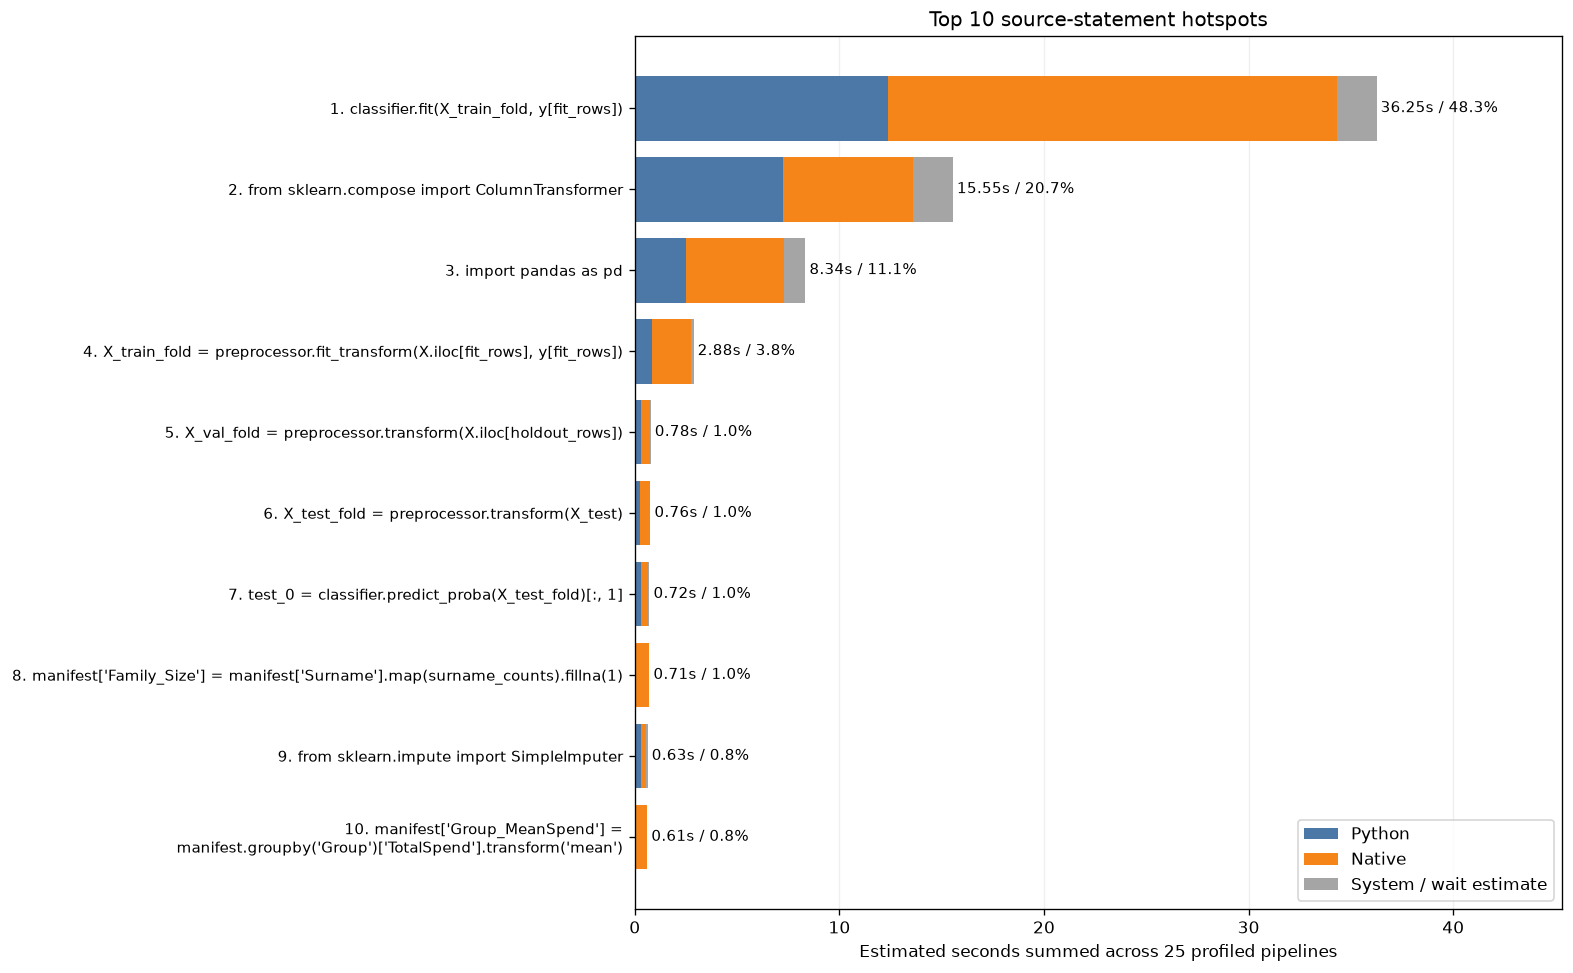

In [16]:
import matplotlib.pyplot as plt
import textwrap

fig, ax = plt.subplots(figsize=(13, 8), layout="constrained")
labels = [f"{row.rank}. " + textwrap.fill(row.operation, 76) for row in top10.itertuples()]
left = [0.0] * len(top10)
for column, label, color in [
    ("python_s", "Python", "#4c78a8"),
    ("native_s", "Native", "#f58518"),
    ("system_s", "System / wait estimate", "#a5a5a5"),
]:
    ax.barh(range(len(top10)), top10[column], left=left, label=label, color=color)
    left = [a + b for a, b in zip(left, top10[column])]
for i, row in enumerate(top10.itertuples()):
    ax.text(row.total_s + 0.2, i, f"{row.total_s:.2f}s / {row.share_of_runs_pct:.1f}%", va="center", fontsize=9)
ax.set_yticks(range(len(labels)), labels, fontsize=9)
ax.invert_yaxis()
ax.set_xlim(0, top10.total_s.max() * 1.25)
ax.set_xlabel("Estimated seconds summed across 25 profiled pipelines")
ax.set_title("Top 10 source-statement hotspots")
ax.legend(loc="lower right")
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)
display(fig)
plt.close(fig)

### Traceable details

`top10_details` retains every pipeline/source location for the Top 10 operations, including records with zero sampled time.
The table below shows the 30 most expensive records. Filter the complete details by `rank` or `pipeline`; repeated occurrences of the same statement within one pipeline remain separate source locations.


In [17]:
top10_details = (
    line_details.merge(top10[["operation", "rank"]], on="operation", how="inner", validate="many_to_one")
    .sort_values(["total_s", "pipeline", "lineno"], ascending=[False, True, True])
    [["rank", "pipeline", "location", "source_file", "lineno", "operation", "source", "modules",
      "python_s", "native_s", "system_s", "total_s"]]
    .reset_index(drop=True)
)
display(top10_details.drop(columns=["source_file", "source"]).head(30).round(4))
# Examples: top10_details.query("rank == 1")
#           top10_details.query("pipeline == 'pipeline_7_1'")

# Verify that detail records reconcile with the aggregate ranking.
reconciled = top10_details.groupby("operation")["total_s"].sum()
assert (reconciled - top10.set_index("operation")["total_s"]).abs().max() < 1e-9
assert (line_details.total_s - line_details[["python_s", "native_s", "system_s"]].sum(axis=1)).abs().max() < 1e-9

,rank,pipeline,location,lineno,operation,modules,python_s,native_s,system_s,total_s
0,1,pipeline_5_3,spaceship_titanic_students/pipeline_5_3.py:107,107,"classifier.fit(X_train_fold, y[fit_rows])",sklearn.base,2.1372,0.1454,0.2956,2.5782
1,1,pipeline_4_3,spaceship_titanic_students/pipeline_4_3.py:108,108,"classifier.fit(X_train_fold, y[fit_rows])",sklearn.base,0.5854,1.6832,0.0108,2.2794
2,1,pipeline_6_2,spaceship_titanic_students/pipeline_6_2.py:120,120,"classifier.fit(X_train_fold, y[fit_rows])",sklearn.base,1.1745,0.3111,0.5096,1.9952
3,1,pipeline_4_2,spaceship_titanic_students/pipeline_4_2.py:108,108,"classifier.fit(X_train_fold, y[fit_rows])",sklearn.base,0.1683,1.7371,0.0046,1.9100
4,1,pipeline_7_1,spaceship_titanic_students/pipeline_7_1.py:132,132,"classifier.fit(X_train_fold, y[fit_rows])",sklearn.base,0.2559,1.5072,0.0298,1.7929
5,1,pipeline_6_1,spaceship_titanic_students/pipeline_6_1.py:120,120,"classifier.fit(X_train_fold, y[fit_rows])",sklearn.base,0.7097,0.9913,0.0872,1.7882
6,1,pipeline_6_3,spaceship_titanic_students/pipeline_6_3.py:132,132,"classifier.fit(X_train_fold, y[fit_rows])",sklearn.base,0.2939,1.4348,0.0253,1.7540
7,1,pipeline_7_1,spaceship_titanic_students/pipeline_7_1.py:120,120,"classifier.fit(X_train_fold, y[fit_rows])",sklearn.base,0.1292,1.5553,0.0332,1.7177
8,1,pipeline_7_3,spaceship_titanic_students/pipeline_7_3.py:132,132,"classifier.fit(X_train_fold, y[fit_rows])",sklearn.base,0.5449,1.0938,0.0765,1.7152
9,1,pipeline_7_2,spaceship_titanic_students/pipeline_7_2.py:132,132,"classifier.fit(X_train_fold, y[fit_rows])",sklearn.base,0.2054,1.4609,0.0277,1.6940


### Identifying worthwhile optimization candidates

- **Model training**: `classifier.fit(...)` is the largest cumulative hotspot. Separate records by model, features, training fold, parameters, and random seed before checking for repeated training; identical statements do not imply identical models. Step 7 changes only the scoring threshold in the computation, making prediction reuse a concrete candidate for further validation.
- **Library initialization**: the first sklearn and pandas imports incur substantial costs, supporting an early experiment with persistent processes or worker reuse. Costs are attributed to the first import site; this does not mean initializing `ColumnTransformer` itself is expensive.
- **Preprocessing**: `fit_transform` and `transform` are concrete operations to investigate. Check whether transformed results can be reused for identical data splits and preprocessing parameters. Caching must preserve training-fold isolation.
- **Feature engineering**: investigate mapping, grouping, and per-value conversion operations according to their ranking. First check whether selected features actually use their outputs, then evaluate redundant computation elimination or vectorization. Pandas calls alone do not justify replacing the entire library.

These priorities identify candidates from a single profiled run per pipeline; they are not validated speedup claims. Sampling attribution can vary between statements. Verify net runtime improvements and predictive quality using repeated, unprofiled comparison runs in the same environment.
